In [2]:
import numpy as np
from scipy.optimize import curve_fit
import matplotlib.pyplot as plt
from matplotlib.ticker import ScalarFormatter

In [3]:
# Definimos el rango de frecuencias 
nu_min = 2.0 # GHz
nu_max = 8.0 # GHz
spw_tot = 16 # Number of spectral windows
dnu = (nu_max - nu_min)/spw_tot
print(dnu)

0.375


In [4]:
# Defino los errores sistemáticos para cada spw
#f = open('rms-per-spw.txt') 
# Este archivo contiene el rms en una región de 9x9=81 pixeles 
# El archivo de la NS tiene 371 valid pixels

#lines = f.readlines()[1:-3]
#f.close()
#flux_err_sys = np.empty(len(lines)) 
#for i,line in enumerate(lines):
#    flux_err_sys[i] = float(line.split('    ')[1])*(371/81)*1000 #Paso a mJy
#    print(f'F_err_sys={flux_err_sys[i]} Jy')

In [5]:
# Leemos los datos del archivo
f = open('flux-NS_2.5mJy.txt')

lines = f.readlines()[1:]
f.close()

nu = np.empty(len(lines)) 
nu_err = np.empty(len(lines)) 
flux = np.empty(len(lines)) 
flux_err = np.empty(len(lines)) 

for i,line in enumerate(lines):
    spw = int(line.split('=')[1].split(' ')[0])
    nu[i] = nu_min + dnu/2.0 + dnu*spw
    #nu_err[i] = dnu/2.0
    flux[i] = float(line.split(' =  ')[1].split(' ')[0])*1000 #Paso a mJy
    #flux_err[i] = np.sqrt( (0.03*flux[i])**2 + flux_err_sys[i]**2 )
    #print(f'spw={spw}, nu={nu[i]} GHz, F={flux[i]} Jy, F_err={flux_err[i]} mJy')

In [6]:
# Agrego los datos viejos
nu2010 = [1.42, 4.86]
#nu2010_err = [0.064, 0.064]
# Agrego un factor de conversión de flujos 2010 a 2018: 1.1 en banda L y 0.75 en banda C
#flux2010 = [0.101*1000*1.1, 0.088*1000*0.751] #Paso a mJy
flux2010 = [0.101*1000, 0.088*1000] #Paso a mJy
#flux2010_err = [flux2010[0]*0.03, flux2010[1]*0.03]

# Armo un vector general para el fitteo
nu2 = np.append(np.append(nu2010[0], nu), nu2010[1])
#nu2_err = np.append(np.append(nu2010_err[0], nu_err), nu2010_err[1])
flux2 = np.append(np.append(flux2010[0],flux), flux2010[1])
#flux2_err = np.append(np.append([0.03*flux2010[0]], flux_err), [0.03*flux2010[1]])

In [7]:
# Defino la función a ajustar
def po(x,F0,alpha):
    """Power law function"""
    return( F0*np.power(x/3.0,alpha) )

In [8]:
# Defino los valores semilla para el ajuste
seed = np.array([50,-0.5])

# Ajusto la función a los datos 
popt, pcov = curve_fit(po, xdata=nu2, ydata=flux2, p0=seed)#, sigma=flux2_err, absolute_sigma=True)
#print(pcov)

perr = np.sqrt(np.diag(pcov))
#print(perr)

for i in range(len(perr)):
    print(str(popt[i])+' +- '+str(perr[i]))

94.91780541522047 +- 0.6040515180366378
-0.09138600134834263 +- 0.011127919611183675


In [15]:
# prepare confidence level curves
nstd = 3.0 # to draw 1-sigma intervals
popt_up = popt + nstd * perr
popt_dw = popt - nstd * perr

nu_fit = np.linspace(1.4, 8., 100)
fit = po(nu_fit, *popt)
fit_up = po(nu_fit, *popt_up)
fit_dw = po(nu_fit, *popt_dw)

for i in range(len(nu_fit)):
    print(nu_fit[i], fit[i])


1.4 101.76439034371164
1.4666666666666666 101.33267991909904
1.5333333333333332 100.92187429793714
1.5999999999999999 100.53011584262671
1.6666666666666665 100.1557810028643
1.7333333333333332 99.79744280016149
1.7999999999999998 99.45384051295984
1.8666666666666667 99.12385496874433
1.9333333333333331 98.80648824578557
2.0 98.50084687475847
2.0666666666666664 98.20612784184685
2.1333333333333333 97.92160685205107
2.2 97.64662842943143
2.2666666666666666 97.3805975205521
2.333333333333333 97.12297233593775
2.4 96.87325821728793
2.466666666666667 96.63100235940243
2.533333333333333 96.39578924809209
2.5999999999999996 96.16723670088294
2.6666666666666665 95.944992417629
2.7333333333333334 95.72873096439929
2.8 95.51815112709284
2.8666666666666663 95.31297358182833
2.933333333333333 95.11293883778404
3.0 94.91780541522047
3.0666666666666664 94.72734822722302
3.1333333333333333 94.54135713849737
3.2 94.35963567852822
3.2666666666666666 94.18199988972741
3.333333333333333 94.00827729397155

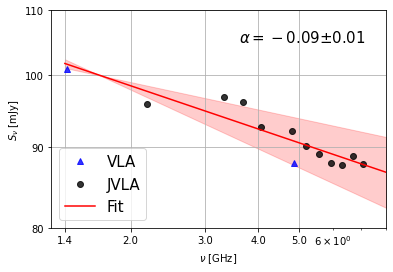

In [11]:
# Grafico datos y ajuste
fig, ax = plt.subplots(1)
plt.rcParams.update({'font.size': 15,
    "font.serif": ["Palatino"]})
plt.grid()
plt.gca().set_xlabel(r'$\nu$ [GHz]')
plt.gca().set_ylabel(r'$S_\nu$ [mJy]')
#plt.errorbar(nu2010, flux2010, yerr=flux2010_err, xerr=nu2010_err, hold=True, ecolor='b', alpha=0.8, fmt='none')
#plt.errorbar(nu, flux, yerr=flux_err, xerr=nu_err, hold=True, ecolor='k', alpha=0.8, fmt='none')
plt.plot(nu2010, flux2010, 'b^', alpha=0.8, label = 'VLA')
plt.plot(nu, flux, 'ko', alpha=0.8, label = 'JVLA')
plt.plot(nu_fit, fit, 'r-', label='Fit')
ax.fill_between(nu_fit, fit_up, fit_dw, alpha=.2, label='', color='r')
plt.title('')
plt.xlim(1.3, 8)
plt.ylim(80, 110)

# LINEAR SCALE
#plt.legend(loc='best')
#plt.gca().yaxis.set_minor_locator(plt.MultipleLocator(10))
#ax.annotate(r'$\alpha =-$' + str(round(abs(popt[1]),2)) + '$\pm$' + str(round(perr[1],2)),
#            xy=(0, 0), xycoords='axes fraction',
#            xytext=(20, 20), textcoords='offset pixels',
#            horizontalalignment='left',
#            verticalalignment='bottom')

# LOGSCALE
plt.legend(loc='lower left')
ax.loglog()
ax.set_xticks([1.4, 2, 3, 4, 5])
ax.set_yticks([80, 90, 100, 110])
ax.get_xaxis().set_major_formatter(ScalarFormatter())
ax.get_yaxis().set_major_formatter(ScalarFormatter())
#plt.gca().yaxis.set_minor_locator(plt.MultipleLocator(10))
ax.annotate(r'$\alpha =-$' + str(round(abs(popt[1]),2)) + '$\pm$' + str(round(perr[1],2)),
            xy=(0.5, 0.75), xycoords='axes fraction',
            xytext=(20, 20), textcoords='offset pixels',
            horizontalalignment='left',
            verticalalignment='bottom')

plt.show()

In [ ]:
fig.savefig('NS.pdf', bbox_inches='tight')

In [ ]:
for i in range(len(nu)):
    print(f'{nu[i]} {nu_err[i]} {flux[i]} {flux_err[i]}')